# Explorando CNNs com Keras para Classificação de Imagens

Vamos compreender como funciona as CNNs e aprender a utiliza-las em um caso prático de Classificação de Imagens utilizando o Dataset MNIST.

In [21]:
# Importando as libs que vamos utilizar
import collections
import matplotlib.pyplot as plt
import random

from keras.datasets import mnist
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from keras.optimizers import Adam
from sklearn.model_selection import train_test_split



## Importando e preparando o Dataset MNIST

In [11]:
# baixando o dataset de treino e teste
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# dividino o dataset em treino e validacao
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, stratify=y_train, test_size=0.2)

# vendo a quantidade de imagens do dataset
print("Quantidade de imagens de treino: ", x_train.shape[0])
print("Quantidade de imagens de validacao: ", x_val.shape[0])
print("Quantidade de imagens de teste: ", x_test.shape[0])

# Contando a quantidade de imagens por classe
counter_train = collections.Counter(y_train)    # retorna um dicionario com a quantidade de imagens por classe
counter_val = collections.Counter(y_val)
counter_test = collections.Counter(y_test)

# Plotando a quantidade de imagens por classe



Quantidade de imagens de treino:  48000
Quantidade de imagens de validacao:  12000
Quantidade de imagens de teste:  10000


In [12]:
# Formatando o dataset para funcionar como entrada para o keras
# as imagens de entrada precisam estar em um array de 4 dimensões, com a forma (num_samples, height, width, num_channels)
# reshape() é usado para mudar a forma do array, sem alterar os dados
x_train = x_train.reshape(x_train.shape[0], 28, 28, 1)
x_val = x_val.reshape(x_val.shape[0], 28, 28, 1)
x_test = x_test.reshape(x_test.shape[0], 28, 28, 1)

# dimensao da imagem de entrada (28x28 pixels, 1 canal para escala de cinza)
input_shape = (28, 28, 1)

# Convertendo valores dos pixels para float32 e normalizando para o intervalo [0, 1]
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
x_val = x_val.astype('float32') / 255.0

## Construindo a CNN

In [13]:
# inicializando a CNN
model = Sequential()

# operação de convolução com filtro 3x3 e funcao de ativação ReLU para não linearidade do modelo
model.add(Conv2D(28, kernel_size=(3, 3), input_shape=input_shape, activation='relu'))

# operacao de Max Pooling 2x2 para diminuir a dimensão do feature map
model.add(MaxPooling2D(pool_size=(2, 2)))

# outra operacao de convolucao + ReLU
model.add(Conv2D(28, kernel_size=(3, 3), activation='relu'))

# operacao de flatten para tranformar a matriz em um vetor
model.add(Flatten())

# camada densa com 128 neuronios + ReLU
model.add(Dense(128, activation='relu'))

# camada de dropout para evitar overfitting
model.add(Dropout(0.5))   # Dropout de 50% dos neuronios

# camada densa de saida com 10 neuronios (para 10 classes) e funcao de ativacao softmax
model.add(Dense(10, activation='softmax'))

# Resumo do modelo
model.summary()


/home/kauanmateus/Documents/visaoComputacionalProjects/vc_venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1783788078.207517   67808 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1783788078.208898   82714 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1783788078.223385   67808 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned abo

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 28)     │           280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 28)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 28)     │         7,084 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3388)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       433,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 442,446 (1.69 MB)

 Trainable params: 442,446 (1.69 MB)

 Non-trainable params: 0 (0.00 B)

## Fazendo o Treinamento da CNN definida acima

Epoch 1/10
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9376 - loss: 0.2102 - val_accuracy: 0.9816 - val_loss: 0.0612
Epoch 2/10
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9764 - loss: 0.0803 - val_accuracy: 0.9857 - val_loss: 0.0484
Epoch 3/10
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9816 - loss: 0.0603 - val_accuracy: 0.9880 - val_loss: 0.0413
Epoch 4/10
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9864 - loss: 0.0440 - val_accuracy: 0.9883 - val_loss: 0.0388
Epoch 5/10
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9887 - loss: 0.0364 - val_accuracy: 0.9893 - val_loss: 0.0410
Epoch 6/10
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9902 - loss: 0.0306 - val_accuracy: 0.9906 - val_loss: 0.0426
Epoch 7/10
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9919 - loss: 0.0255 - val_accuracy: 0.9902 - val_loss: 0.0417
Epoch 8/10
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9918 - loss: 0

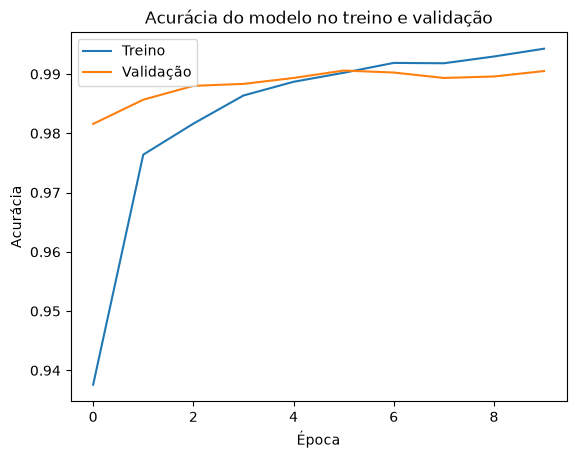

In [18]:
# Definindo o otimizador, funcao de perda e metrica de eficiencia
# Adam é um otimizador que combina o método de gradiente descendente com momentum e RMSProp, ajustando a taxa de aprendizado para cada parâmetro individualmente.
adam_optimizer = Adam(learning_rate=0.001)
loss_function = 'sparse_categorical_crossentropy' # função de perda para classificação multi-classe com rótulos inteiros

# compilando o modelo
model.compile(optimizer=adam_optimizer, loss=loss_function, metrics=['accuracy'])

# Treinando o modelo
history = model.fit(x=x_train, y=y_train, validation_data=(x_val, y_val), batch_size=16, epochs=10, shuffle=False)

# Plotando o historico de treino
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Acurácia do modelo no treino e validação')
plt.ylabel('Acurácia')
plt.xlabel('Época')
plt.legend(['Treino', 'Validação'], loc='upper left')
plt.show()

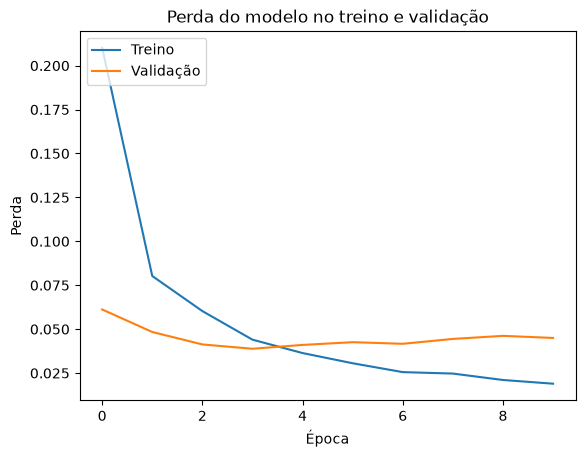

In [19]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Perda do modelo no treino e validação')
plt.ylabel('Perda')
plt.xlabel('Época')
plt.legend(['Treino', 'Validação'], loc='upper left')
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9915 - loss: 0.0400
Perda: 0.040 
Acuracia: 0.992
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
Valor predito: 0


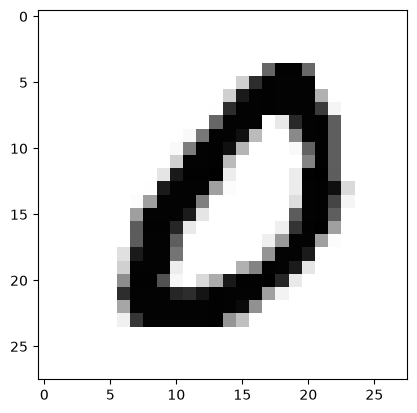

In [24]:
# Avaliando a CNN treinada
score = model.evaluate(x_test, y_test)

print(f"Perda: {score[0]:.3f} \nAcuracia: {score[1]:.3f}")

# imprimindo uma imagem aleatoria do dataset de teste e o valor predito pelo modelo
image_index = random.randint(0, x_test.shape[0]-1)
plt.imshow(x_test[image_index].reshape(28, 28), cmap='Greys')

pred = model.predict(x_test[image_index].reshape(1, 28, 28, 1))
print(f"Valor predito: {pred.argmax()}")